# AlexNet with Tensorgami

Load a model, call `tg.draw` with an example input, and the figure shows inline. Nothing is
written to disk until you call `save`, and the model itself is left untouched. This notebook
shows the options one at a time: level of detail, view, style, direction and layout.

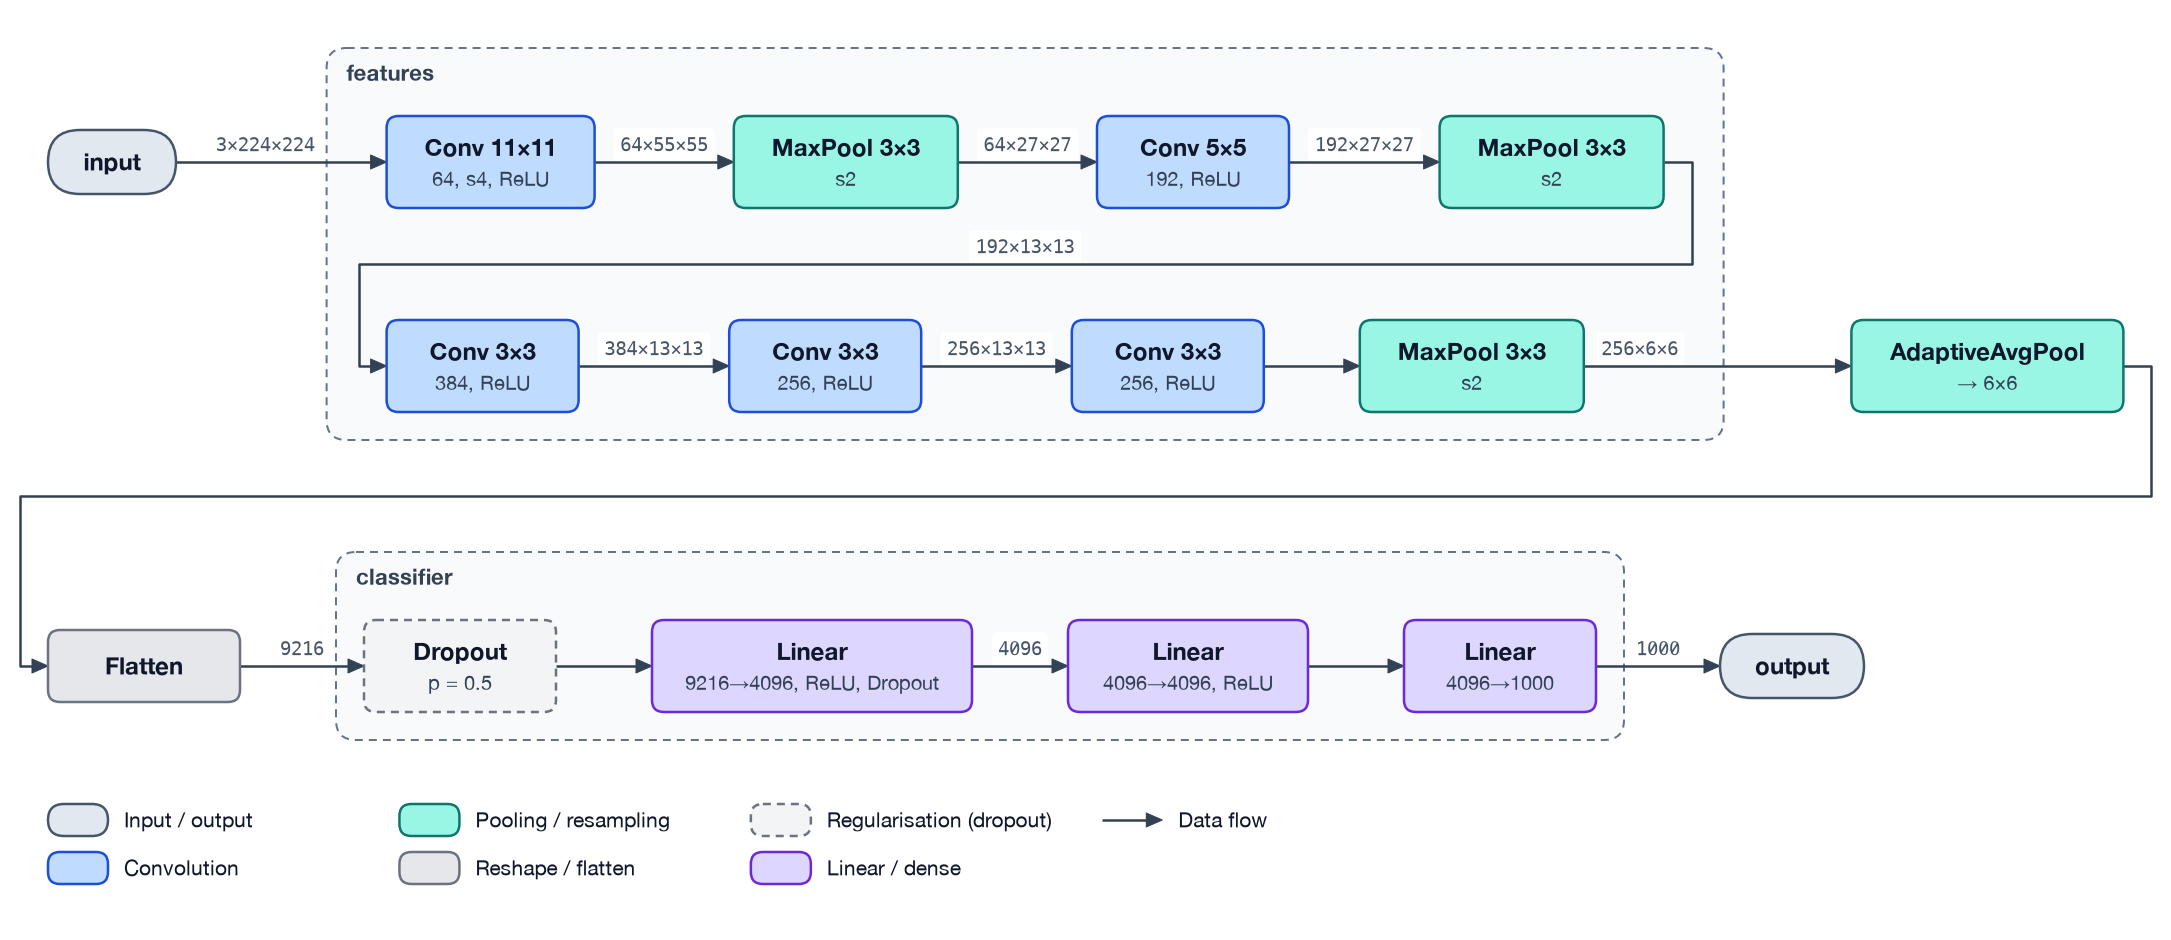

In [1]:
import torch
from alexnet import AlexNet  # examples/alexnet.py: AlexNet as defined in torchvision

import tensorgami as tg

model = AlexNet()
x = torch.randn(1, 3, 224, 224)  # one image, with the batch dimension

tg.draw(model, x)  # layer level, block view, default style

## Level of detail

`level` by number or name: 0 `"system"`, 1 `"stages"` (the model's direct sub-modules),
2 `"layers"` (the default), 3 `"operators"` (everything traced).

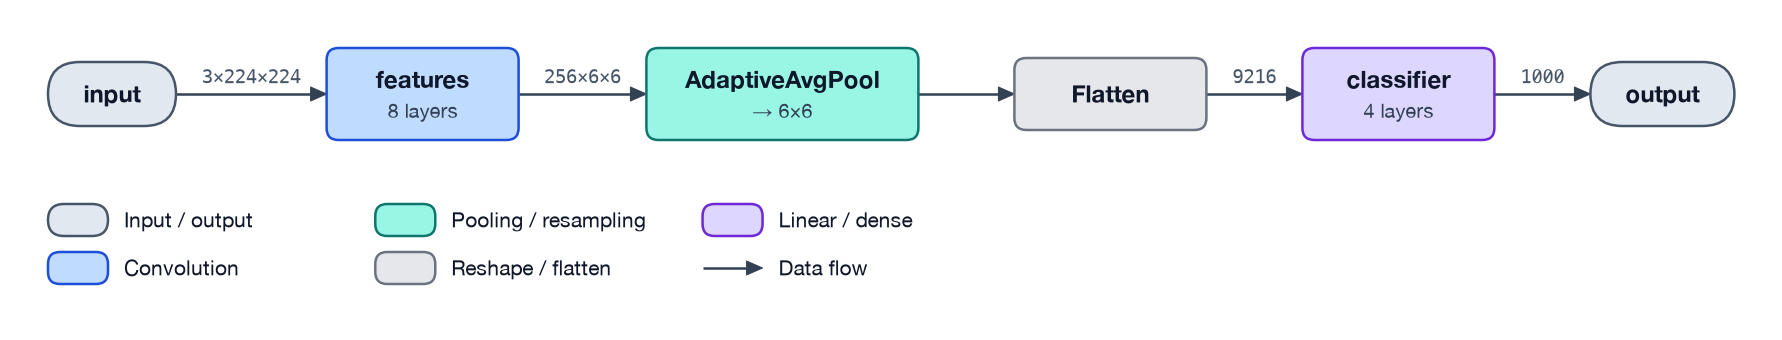

In [2]:
tg.draw(model, x, level="stages")

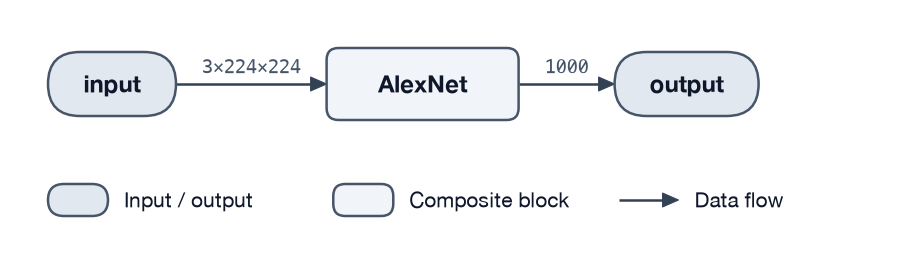

In [3]:
tg.draw(model, x, level="system")

## Views

`view="volume"` draws every layer as the tensor it produces (C × H × W), as in the original
paper; the dense layers are thin bars. (`view="unrolled"` is for recurrent models, see
`tour.ipynb`.)

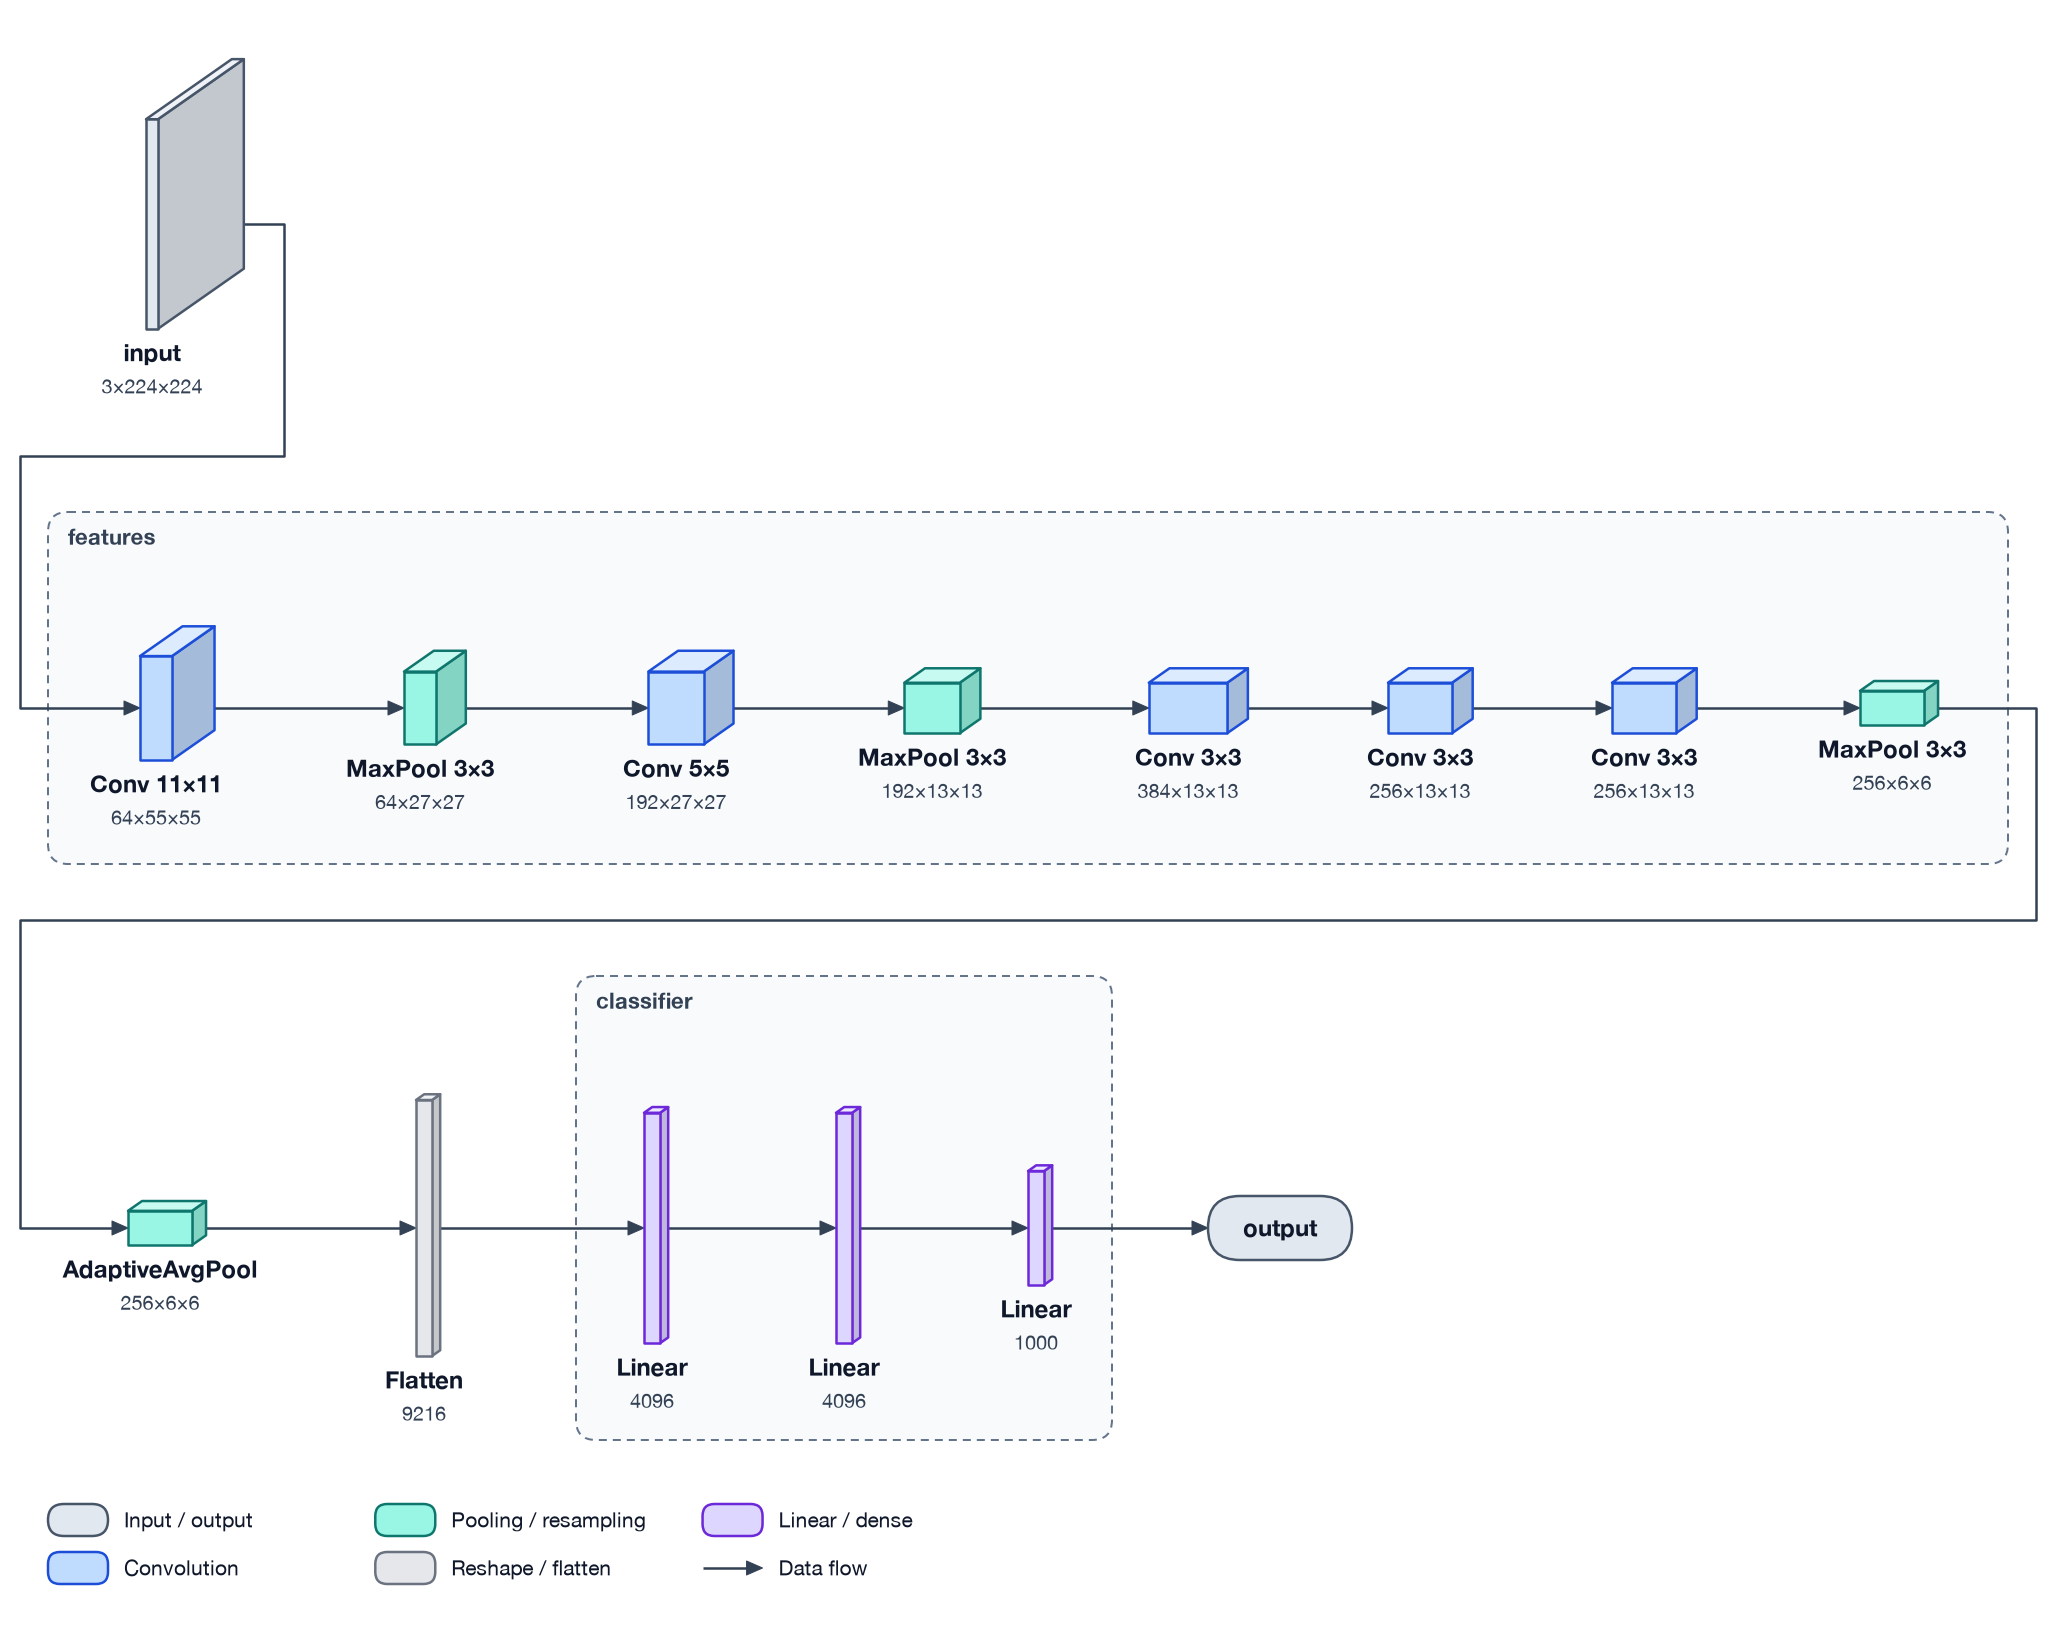

In [4]:
tg.draw(model, x, view="volume")

## Styles

`style="default"`, `"origami"` (upright cards left → right) or `"origami-extended"` (flat cards,
top → bottom), or the path of your own `.toml` style.

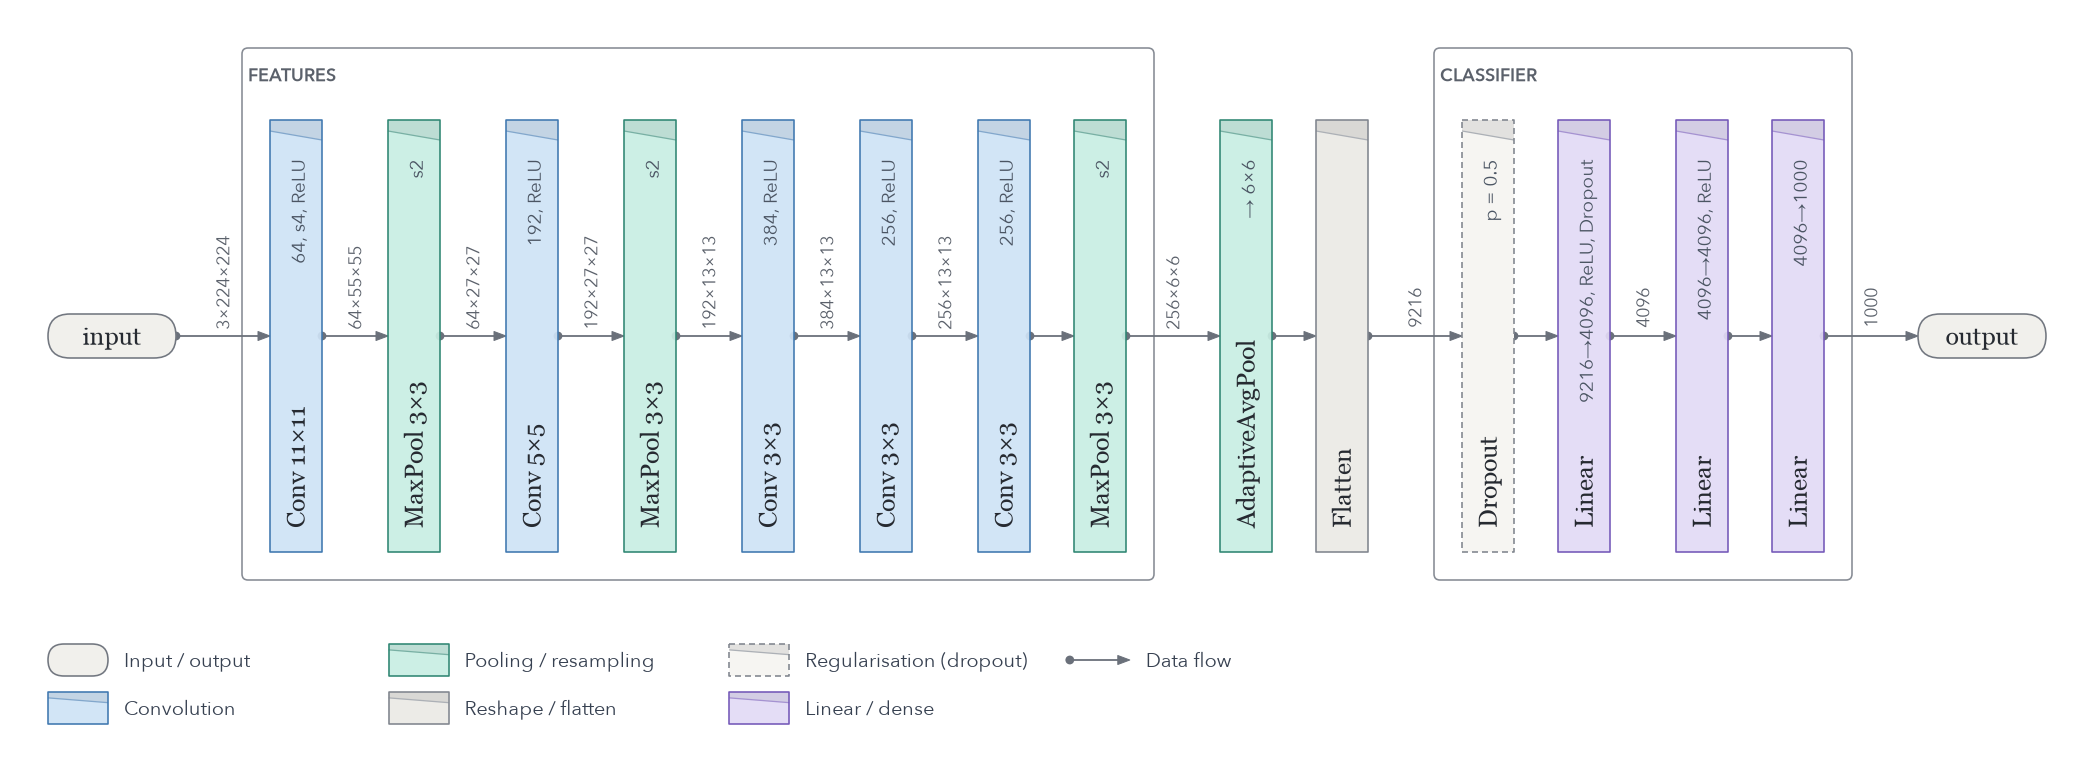

In [5]:
tg.draw(model, x, style="origami")

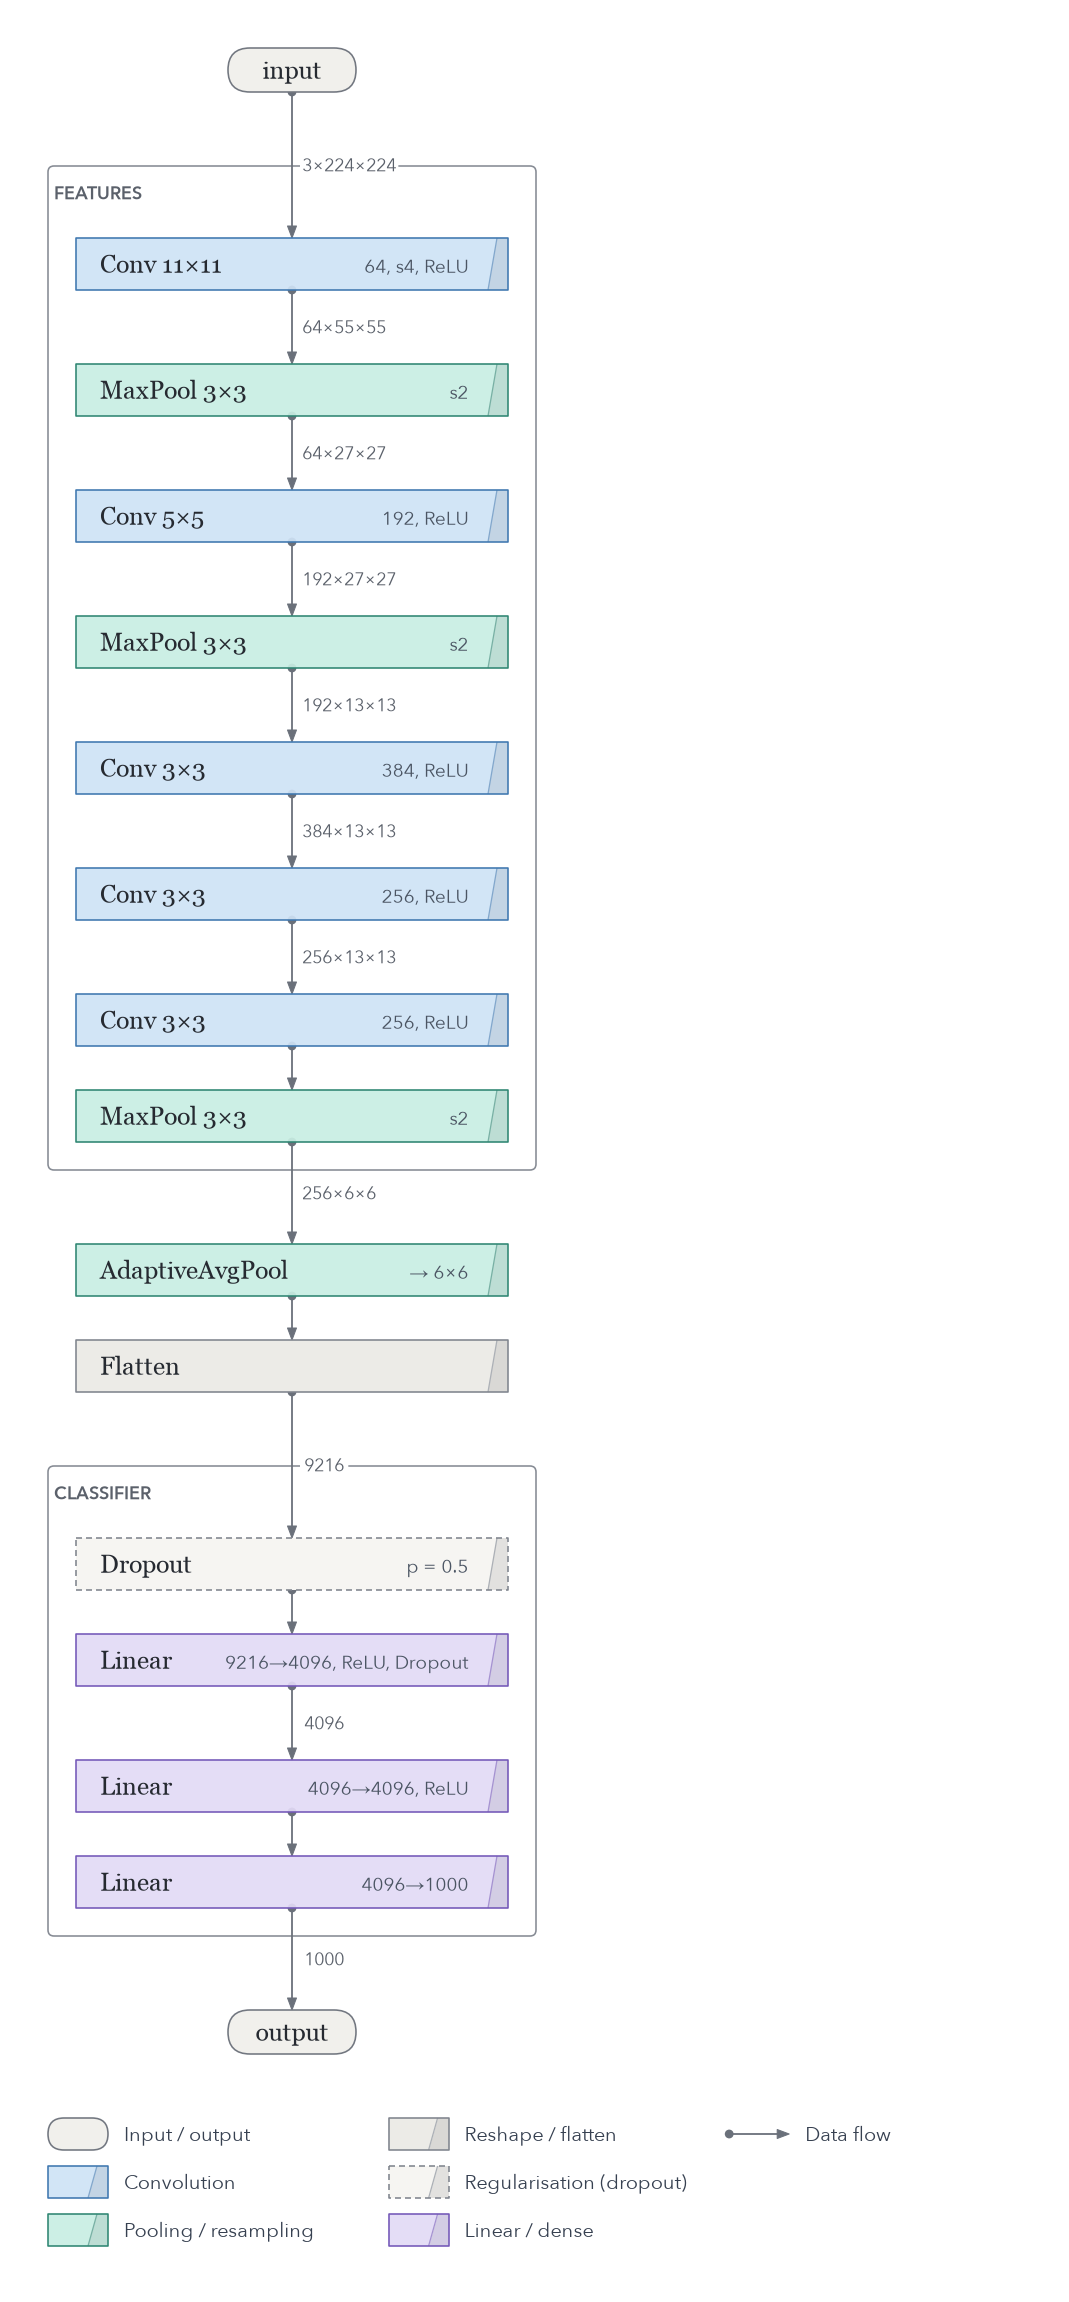

In [6]:
tg.draw(model, x, style="origami-extended")

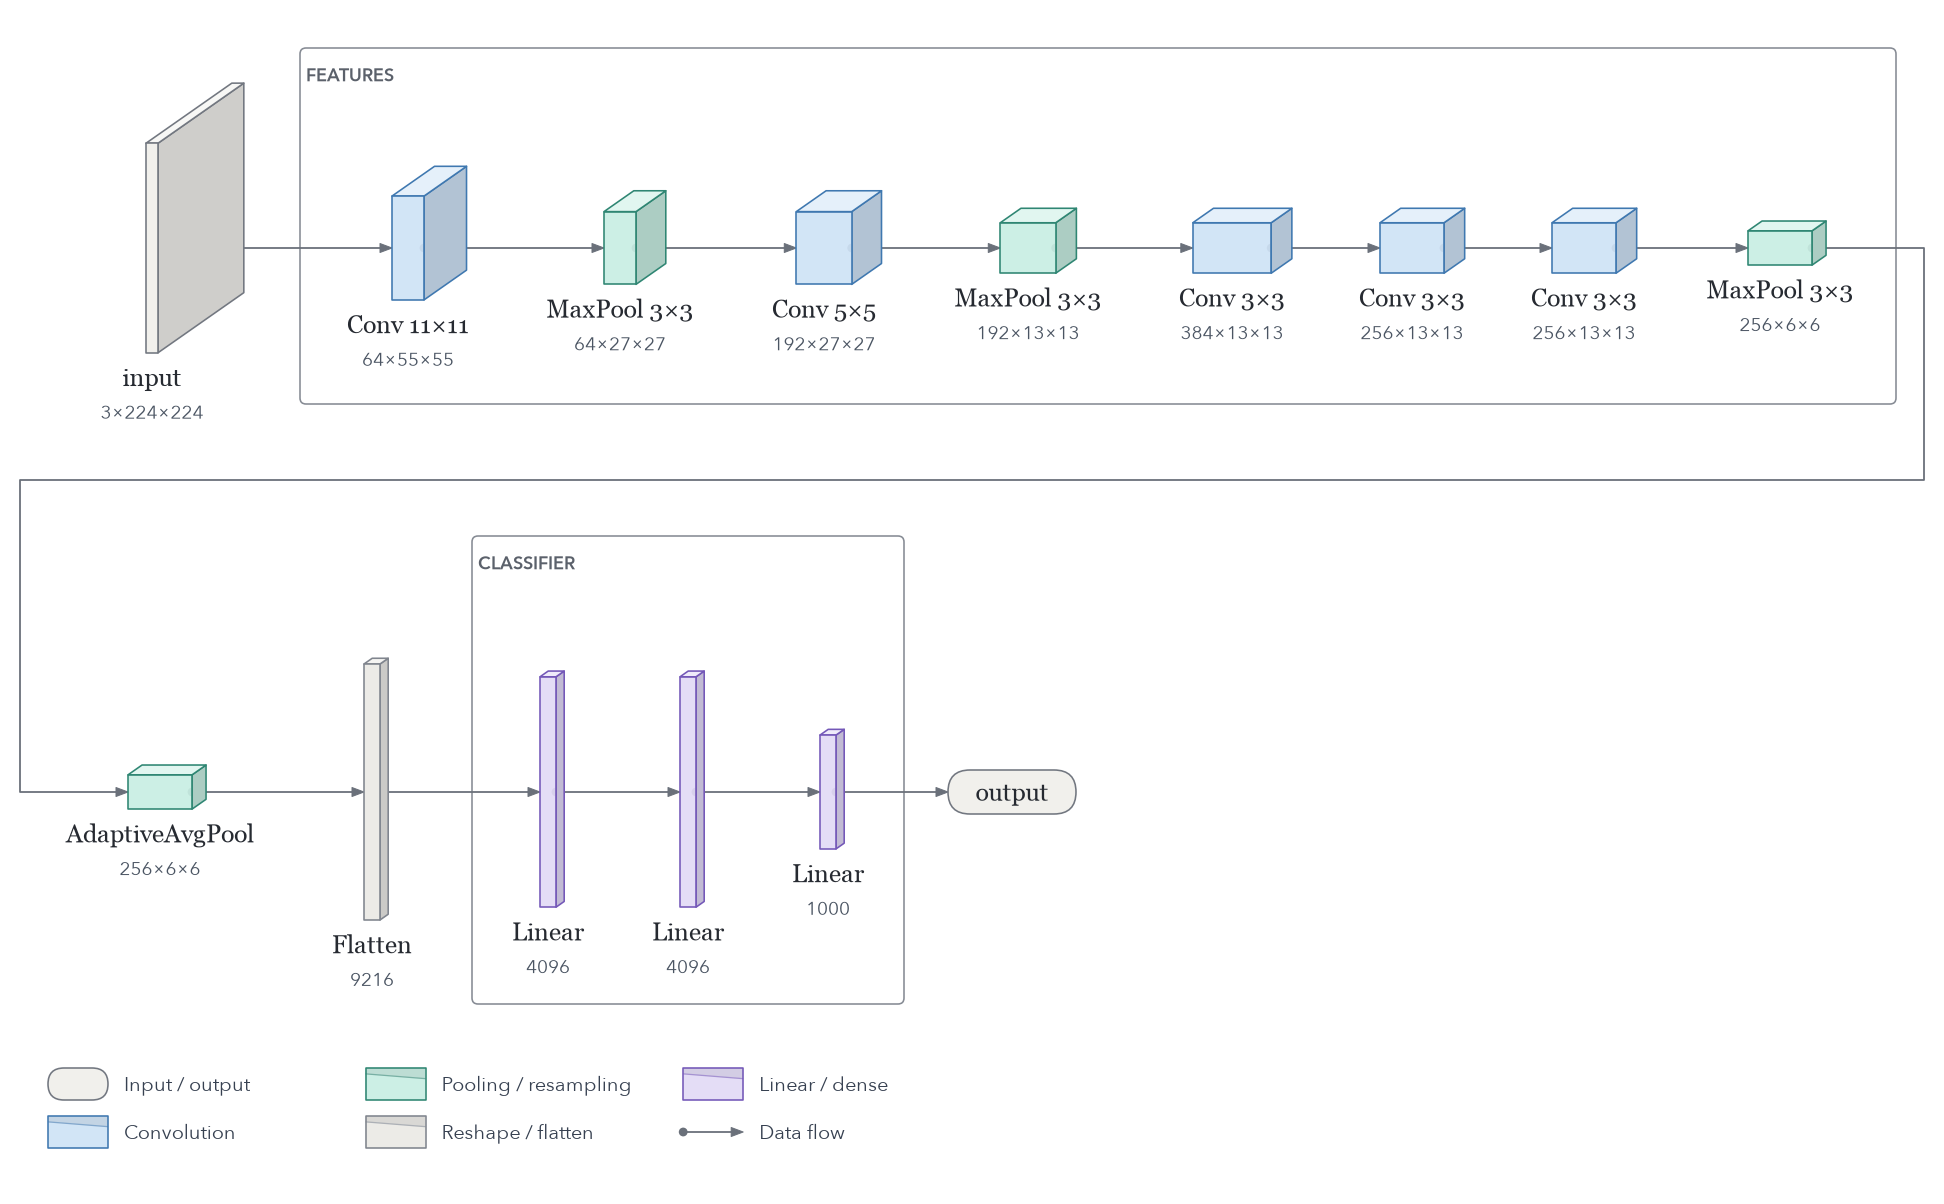

In [7]:
tg.draw(model, x, style="origami", view="volume")

## Direction and layout options

`direction="TB"` runs top → bottom; any layout option can be passed by name, e.g.
`legend=False`, `wrap_width=None` (keep one row) or `shapes_on_edges=False`.

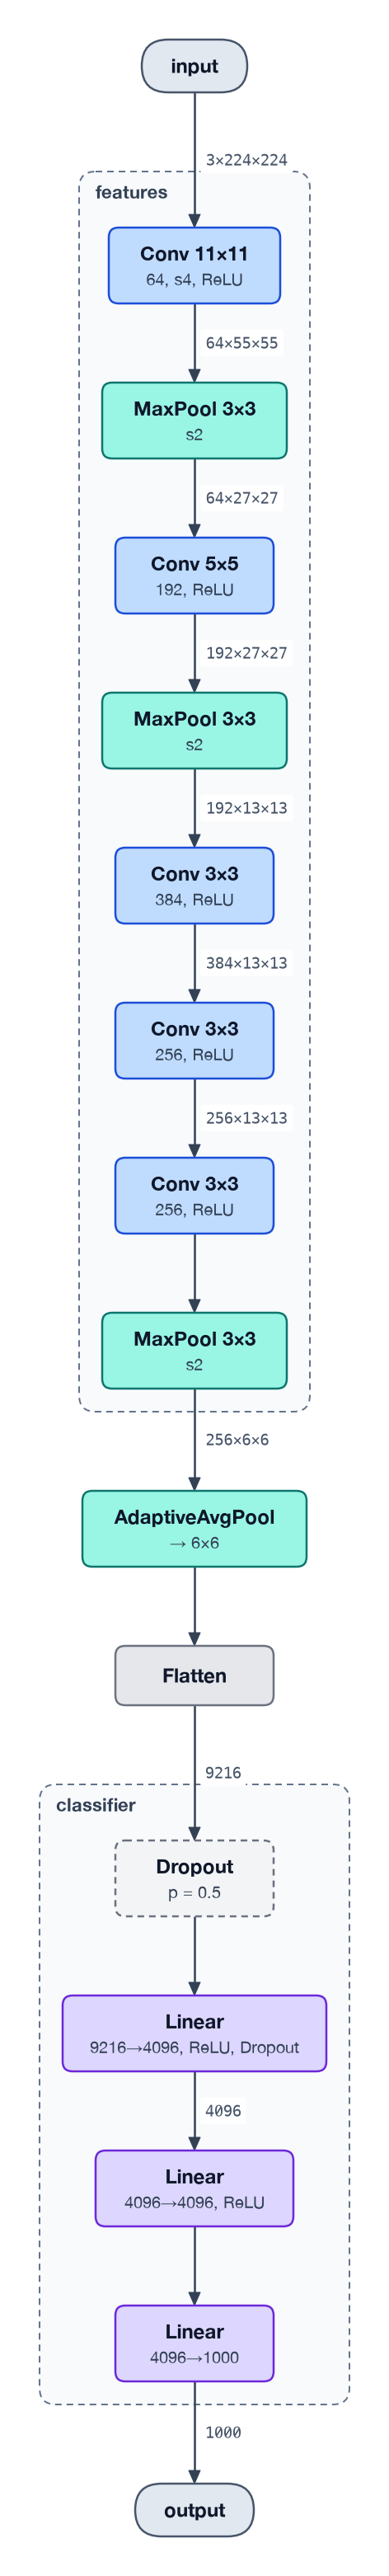

In [8]:
tg.draw(model, x, direction="TB", legend=False)

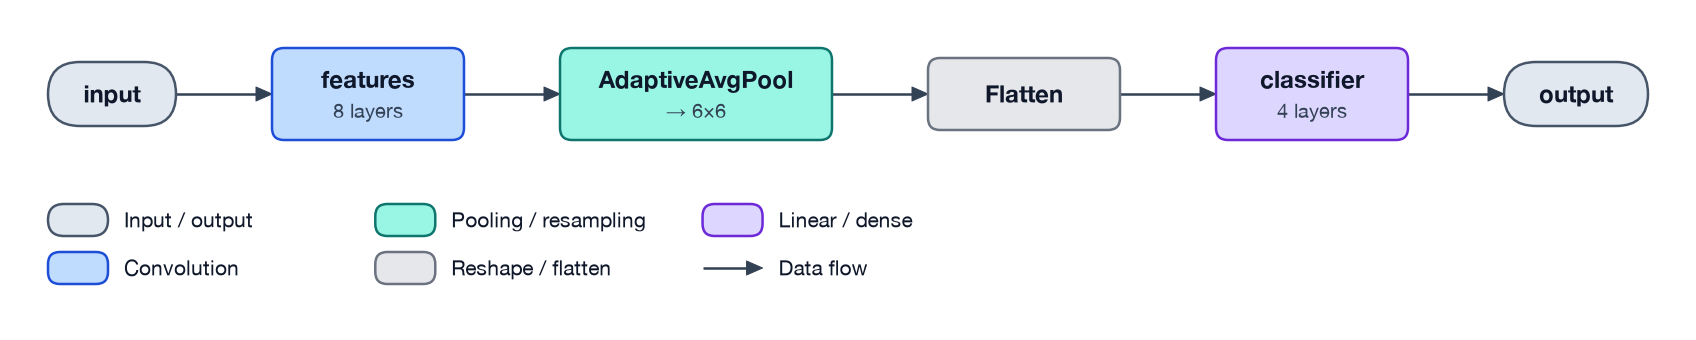

In [9]:
tg.draw(model, x, level="stages", wrap_width=None, shapes_on_edges=False)

## Saving

The format follows the suffix: `.png` (choose the `dpi`), `.svg`, `.pdf`, `.jpg`, `.tif`.
Here into a temporary folder, so the example writes nothing next to the notebook.

In [10]:
import tempfile
from pathlib import Path

folder = Path(tempfile.mkdtemp())  # a scratch folder here; any path of yours works
fig = tg.draw(model, x)
for path in (fig.save(folder / "alexnet.png", dpi=300), fig.save(folder / "alexnet.svg")):
    print(f"{path.name}: {path.stat().st_size / 1024:.0f} kB")

alexnet.png: 234 kB
alexnet.svg: 20 kB


Tensorgami figures can be panels of your own matplotlib layouts:

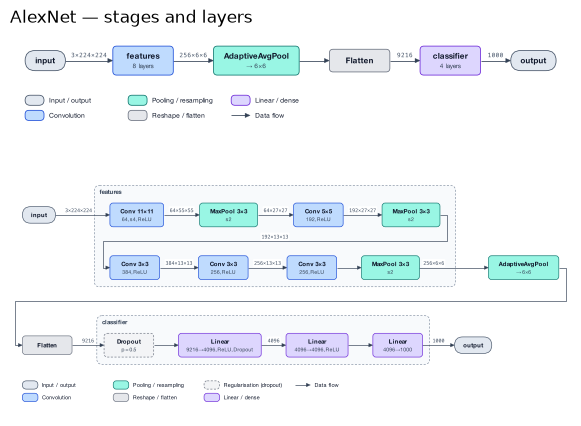

In [11]:
import matplotlib.pyplot as plt

stages, layers = tg.draw(model, x, level="stages"), tg.draw(model, x)
heights = [f.size[1] / f.size[0] for f in (stages, layers)]  # each panel keeps its proportions
panels, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5), height_ratios=heights)
stages.draw_on(top)
layers.draw_on(bottom)
top.set_title("AlexNet — stages and layers", loc="left")
plt.show()